# Normalized dataset: blueberry

Builds `normalized/blueberry/`, one dataset for **blueberry** merged from the sources surveyed in `plague.ipynb` and `growth.ipynb`. All labels use one class vocabulary. The goal is **correct labels, not many labels**: when a label cannot be trusted or reconciled, it is dropped, and this notebook says why and counts it.

```
normalized/blueberry/
  images/                                 every image, flat, named <source>_<n>.<ext>
  labels/classification/condition.csv     image,class   plant condition (healthy / disease / pest / deficiency)
  labels/classification/maturity.csv      image,class   fruit maturity, only from sources that label it per image
  labels/classification/classes.json      class lists of both axes
  labels/detection/condition/<stem>.txt  YOLO "cls cx cy w h", normalized to 0-1, clipped to the image (+ classes.txt)
  labels/detection/maturity/<stem>.txt   same format, plant-stage objects only: flower, bud, fruit__<stage> (+ classes.txt)
  labels/segmentation/condition/<stem>.txt  YOLO-seg "cls x1 y1 x2 y2 ...", normalized polygons, one line per polygon (+ classes.txt)
  labels/segmentation/maturity/<stem>.txt   same format, plant-stage objects only (+ classes.txt)
  manifest.csv                            image, source, source_ref, license, width, height, group, dhash, exif_fix, label_space
```

**Two label axes, two models.** Like classification, detection and segmentation are split into `condition` (healthy / disease / pest / deficiency objects) and `maturity` (flower, bud, fruit stages). Each folder has its **own** `classes.txt` and class ids, so each trains its own model. An image can have a file in both.

**Why this format.** Image sizes go from about 60 px to 8,000 px, so boxes and polygons are stored **normalized** (0–1) as centre-x, centre-y, width, height. These values do not depend on image size, and YOLO tools read them as they are. Polygons are lighter than masks and can be rasterized at any resolution when training.

**Rules used for every source**
1. **Image-level classes taken from boxes.** A `condition` comes from boxes only when the source labels conditions on every image and all condition boxes in the image share one class. Images with mixed classes are left out of `condition.csv` (counted below).
2. **Healthy is never inferred from missing boxes.** It comes only from an explicit healthy label.
3. **Coarse source classes are not split.** When a source class is coarser than the vocabulary, it maps to a coarse class. Example: Strawberry_12 `unripe fruit` becomes `fruit__unripe`, which covers green, white and turning.
4. **Augmented copies and byte-identical duplicates are dropped.** Near-duplicates across sources share one `group`. A near-duplicate has the same 64-bit dHash, confirmed by a 256-bit dHash at most 10 bits apart. If their classification labels disagree, those labels are removed.
5. **Boxes** are converted from each source's convention (pixel xywh, YOLO, COCO) and clipped to the image. Boxes under 2 px after clipping are dropped. Boxes that reached more than 2 px outside are counted.
6. **Detection files.** An image has a detection file only if its source boxes objects in it. An **empty** file means a verified negative. Images with no boxes in a detection source get **no** file, because "no box" does not prove "nothing there".
7. **EXIF orientation.** If the annotation size matches the stored pixels, the EXIF tag is dropped and the pixels are kept. Otherwise the photo is rotated upright (the frame YOLO tools and AgML annotations use). Every other image is copied byte for byte.

**Columns for training**
- `group` is the **leakage key**: split train/val/test by `group`, never by image. It covers Roboflow stems, augmented copies, video sequences, pepper ids, capture sessions and near-duplicates.
- `label_space` lists the detection classes the image's source actually annotates. Sources label different things (a fruit-stage set never boxes diseases), so mask the loss of classes outside `label_space` instead of treating them as background.

In [1]:
import hashlib
import io
import json
import os
import re
import shutil
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from huggingface_hub import HfApi, HfFileSystem, hf_hub_download, snapshot_download
from PIL import Image, ImageDraw, ImageOps

if Path.cwd().name == "normalization":  # notebooks live in normalization/, paths below are relative to the repo root
    os.chdir("..")

CROP = "blueberry"
OUT = Path("normalized") / CROP
DATA_DIR = Path("data")
EXAMPLE_DIR = Path("examples") / "normalized"
EXAMPLE_DIR.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(0)

shutil.rmtree(OUT, ignore_errors=True)  # the notebook always rebuilds its crop from scratch
for sub in ("images", "labels/classification", *(f"labels/{t}/{a}" for t in ("detection", "segmentation") for a in ("condition", "maturity"))):
    (OUT / sub).mkdir(parents=True)

IMAGES = {}                                   # image name -> manifest row
CLASSIFICATION = {"condition": {}, "maturity": {}}
CONFLICTS = {"condition": set(), "maturity": set()}
SHAPES = {(t, a): {} for t in ("detection", "segmentation") for a in ("condition", "maturity")}  # (task, axis) -> image -> lines
MATURITY_STATES = {"green", "white", "turning", "ripe", "overripe", "unripe", "half_ripe", "breaker", "reddish"}


def axis_of(cls):
    # plant-stage objects go to the maturity model; everything else (healthy, lesions, affected organs, diseased fruit) to condition
    return "maturity" if cls in ("flower", "bud") or (cls.startswith("fruit__") and cls.split("__")[1] in MATURITY_STATES) else "condition"


def axis_classes(task, axis):
    return [c for c in CLASSES[task] if axis_of(c) == axis]


def has_label(name):
    return any(name in d for d in (*CLASSIFICATION.values(), *SHAPES.values()))
LABEL_SPACE = {}                              # source -> detection classes the source annotates
DROPPED = Counter()                           # (source, reason) -> count
NOTES = Counter()                             # (source, note) -> count, things kept but worth knowing
SERIAL = Counter()

/home/mauri/.pyenv/versions/3.12.12/envs/p312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Helpers

`add_image`, `add_class`, `add_boxes` and `add_polygon` are the only functions that write labels. They apply rules 5–7 above and record what they drop.

In [2]:
def dhash(img):
    # difference hashes: 64-bit (hex, for bucketing) and 256-bit (bits, to confirm a match). Resized or re-encoded copies agree.
    img.draft("L", (128, 128))  # fast JPEG decode at reduced size
    gray = img.convert("L")
    bits = {n: (lambda a: a[:, 1:] > a[:, :-1])(np.asarray(gray.resize((n + 1, n), Image.BILINEAR), dtype=np.int16)).ravel() for n in (8, 16)}
    # "0x" prefix: a bare hex string like "1e00..." makes pandas' CSV parser read a float with a huge exponent (segfault in pandas 2.3)
    return f"0x{int(''.join('1' if b else '0' for b in bits[8]), 2):016x}", bits[16]


def add_image(data, source, ref, license, group, frame=None):
    # data: encoded bytes (copied unchanged when possible) or a PIL image (saved as PNG).
    # frame: (W, H) the source annotated on, if it records one. Returns (name, W, H), or None if the image is dropped.
    img = Image.open(io.BytesIO(data)) if isinstance(data, bytes) else data
    orientation = img.getexif().get(274, 1) if isinstance(data, bytes) else 1
    try:
        digest = dhash(Image.open(io.BytesIO(data)) if isinstance(data, bytes) else img)  # also proves the file decodes
    except OSError:
        DROPPED[(source, "image file cannot be decoded")] += 1
        return None
    SERIAL[source] += 1
    stem = f"{source}_{SERIAL[source]:06d}"
    exif_fix = ""
    if isinstance(data, bytes) and orientation == 1 and img.format in ("JPEG", "MPO", "PNG"):
        name = stem + (".png" if img.format == "PNG" else ".jpg")
        (OUT / "images" / name).write_bytes(data)
    else:
        jpeg = img.format in ("JPEG", "MPO")
        if orientation != 1 and frame is not None and tuple(frame) == img.size:
            exif_fix = "tag dropped (annotations on stored pixels)"
        elif orientation != 1:
            img, exif_fix = ImageOps.exif_transpose(img), "rotated upright"
            digest = dhash(img)
        name = stem + (".jpg" if jpeg else ".png")
        if jpeg:
            img.convert("RGB").save(OUT / "images" / name, quality=95)
        else:
            img.save(OUT / "images" / name, compress_level=3)
    W, H = img.size
    if frame is not None and tuple(frame) != (W, H):
        (OUT / "images" / name).unlink()
        DROPPED[(source, "image size differs from the annotation size")] += 1
        return None
    IMAGES[name] = {"image": name, "source": source, "source_ref": ref, "license": license, "width": W, "height": H,
                    "group": f"{source}:{group}", "dhash": digest[0], "_bits": digest[1], "exif_fix": exif_fix}
    return name, W, H


def add_class(axis, name, cls):
    assert cls in CLASSES[axis], (axis, cls)
    old = CLASSIFICATION[axis].setdefault(name, cls)
    if old != cls:
        CONFLICTS[axis].add(name)


def add_boxes(name, boxes, negative=False):
    # boxes: [(x, y, w, h, class)] in pixels of the written image. negative=True writes an empty file for a verified negative.
    if not boxes and not negative:
        return
    W, H, source = IMAGES[name]["width"], IMAGES[name]["height"], IMAGES[name]["source"]
    lines = defaultdict(list)
    for x, y, w, h, cls in boxes:
        x0, y0, x1, y1 = max(0, x), max(0, y), min(W, x + w), min(H, y + h)
        if x < -2 or y < -2 or x + w > W + 2 or y + h > H + 2:
            NOTES[(source, "box clipped (reached > 2 px outside the image)")] += 1
        if x1 - x0 < 2 or y1 - y0 < 2:
            DROPPED[(source, "box < 2 px after clipping")] += 1
            continue
        axis = axis_of(cls)
        lines[axis].append(f"{axis_classes('detection', axis).index(cls)} {(x0 + x1) / 2 / W:.6f} {(y0 + y1) / 2 / H:.6f} {(x1 - x0) / W:.6f} {(y1 - y0) / H:.6f}")
    if boxes and not lines:
        DROPPED[(source, "image lost all its boxes (not written as a negative)")] += 1
        return
    if negative:  # only condition negatives exist (healthy scenes): no source verifies "no flower / fruit here"
        SHAPES[("detection", "condition")].setdefault(name, [])
    for axis, axis_lines in lines.items():
        SHAPES[("detection", axis)].setdefault(name, []).extend(axis_lines)


def add_polygon(name, flat, cls):
    # flat: [x0, y0, x1, y1, ...] in pixels of the written image
    W, H, source = IMAGES[name]["width"], IMAGES[name]["height"], IMAGES[name]["source"]
    if len(flat) < 6:
        DROPPED[(source, "polygon with < 3 points")] += 1
        return
    xy = [f"{min(max(v / (W if i % 2 == 0 else H), 0), 1):.6f}" for i, v in enumerate(flat)]
    axis = axis_of(cls)
    SHAPES[("segmentation", axis)].setdefault(name, []).append(f"{axis_classes('segmentation', axis).index(cls)} " + " ".join(xy))


def condition_from_boxes(name, conditions):
    # rule 1: an image-level condition only if every condition box in the image agrees
    conditions = set(conditions)
    if len(conditions) == 1:
        add_class("condition", name, conditions.pop())
    elif len(conditions) > 1:
        DROPPED[(IMAGES[name]["source"], "condition: boxes of different conditions in one image")] += 1


def show_mapping(mapping):
    for k, v in mapping.items():
        print(f"  {str(k):<34} -> {v}")


def card_class_names(repo, column="objects"):
    info = HfApi().dataset_info(repo).card_data["dataset_info"]
    info = info[0] if isinstance(info, list) else info
    for feature in info["features"]:
        if feature["name"] == column:
            if "struct" in feature:
                names = next(s for s in feature["struct"] if s["name"] == "categories")["list"]["class_label"]["names"]
            else:
                names = feature["dtype"]["class_label"]["names"]
            return [names[str(i)] for i in range(len(names))]


def parquet_files(repo, folder="data"):
    root = snapshot_download(repo, repo_type="dataset", allow_patterns=[f"{folder}/*.parquet", "README.md"])
    return sorted(Path(root, folder).glob("*.parquet"))


def parquet_rows(files, columns):
    # row by row, one row group in memory at a time
    for path in files:
        pf = pq.ParquetFile(path)
        for group in range(pf.num_row_groups):
            yield from pf.read_row_group(group, columns=columns).to_pylist()


def load_coco(folder, splits, json_name):
    # -> list of (split, image dict, [annotation dicts])
    out = []
    for split in splits:
        coco = json.loads(Path(folder, split, json_name).read_text())
        names = {c["id"]: c["name"] for c in coco["categories"]}
        by_image = defaultdict(list)
        for a in coco["annotations"]:
            by_image[a["image_id"]].append({**a, "class": names[a["category_id"]]})
        out += [(split, img, by_image[img["id"]]) for img in coco["images"]]
    return out


def rf_stem(file_name):
    # Roboflow names every copy <source>_<ext>.rf.<hash>.<ext>: copies of one photo share the stem
    return re.sub(r"\.rf\.[0-9a-zA-Z]+", "", file_name)

## Class vocabulary

Detection and segmentation classes are named `<object>__<state>`:
- `leaf__healthy` = a whole leaf box (PlantDoc).
- `lesion__<disease>` = a lesion box or polygon (PlantSeg).
- `fruit__<stage>` = a fruit box.
- `affected__<condition>` = a box around the affected organ or region (Strawberry_12 draws these around a diseased fruit, a leaf with pests, a deficient leaf).

Plant parts with no state are plain (`flower`, `bud`). Keeping the object in the name stops a leaf-sized box and a lesion-sized box of the same disease from being merged into one class.

Blueberry fruit is labeled in two stages only (`unripe`, `ripe`). No source labels maturity per image, so `maturity.csv` is empty. Disease data is **thin** (PlantSeg, 36–47 images per disease, web images).

In [3]:
CLASSES = {
    "condition": ["healthy", "anthracnose", "botrytis_blight", "mummy_berry", "rust", "scorch"],
    "maturity": [],
    "detection": ["fruit__unripe", "fruit__ripe", "leaf__healthy", "lesion__anthracnose", "lesion__botrytis_blight",
                  "lesion__mummy_berry", "lesion__rust", "lesion__scorch"],
    "segmentation": ["fruit__unripe", "fruit__ripe", "lesion__anthracnose", "lesion__botrytis_blight", "lesion__mummy_berry",
                     "lesion__rust", "lesion__scorch"],
}

for task, axis in SHAPES:
    print(f"{task}/{axis}: {axis_classes(task, axis)}")


detection/condition: ['leaf__healthy', 'lesion__anthracnose', 'lesion__botrytis_blight', 'lesion__mummy_berry', 'lesion__rust', 'lesion__scorch']
detection/maturity: ['fruit__unripe', 'fruit__ripe']
segmentation/condition: ['lesion__anthracnose', 'lesion__botrytis_blight', 'lesion__mummy_berry', 'lesion__rust', 'lesion__scorch']
segmentation/maturity: ['fruit__unripe', 'fruit__ripe']


## PlantVillage: `BrandonFors/Plant-Diseases-PlantVillage-Dataset`

Lab photos of single leaves (CC0 in the HF metadata). Each image has one `Crop___condition` label, which goes straight to `condition`. Only classes of this crop are used. ⚠️ The images are lab photos on plain backgrounds, so do not validate a field model on them.

In [4]:
from datasets import Image as HFImage
from datasets import load_dataset


def load_plantvillage(mapping):
    pv = load_dataset("BrandonFors/Plant-Diseases-PlantVillage-Dataset")
    names = pv["train"].features["label"].names
    assert set(mapping) <= set(names), set(mapping) - set(names)
    wanted = {names.index(k): v for k, v in mapping.items()}
    for split in pv:
        ds = pv[split].cast_column("image", HFImage(decode=False))
        idx = [i for i, label in enumerate(ds["label"]) if label in wanted]
        for i, row in zip(idx, ds.select(idx)):
            item = row["image"]
            added = add_image(item["bytes"] or Path(item["path"]).read_bytes(), "plantvillage", f"{split}/{i}",
                              "CC0 1.0 (HF metadata)", f"{split}/{i}")
            if added:
                add_class("condition", added[0], wanted[row["label"]])


load_plantvillage({"Blueberry___healthy": "healthy"})

## PlantSeg v3: `XuVV/plantsegv3`

In-the-wild disease photos with **lesion polygons and boxes**. One disease per image, which goes to `condition`. Boxes become `lesion__<disease>` detections and polygons become `lesion__<disease>` segmentation, one line per polygon part. ⚠️ **CC BY-NC-ND 4.0** (non-commercial), and the images are web-scraped. There is no healthy class.

In [5]:
def load_plantseg(prefix, diseases):
    files = sorted((Path(snapshot_download("XuVV/plantsegv3", repo_type="dataset")) / "data").glob("*.parquet"))
    found = Counter()
    for path in files:
        pf = pq.ParquetFile(path)
        for g in range(pf.num_row_groups):
            if not any(a.startswith(prefix) for a in pf.read_row_group(g, columns=["answer"]).column("answer").to_pylist()):
                continue
            for row in pf.read_row_group(g, columns=["image", "file_name", "width", "height", "answer", "bboxes", "segmentations"]).to_pylist():
                if not row["answer"].startswith(prefix):
                    continue
                found[row["answer"]] += 1
                cond = diseases[row["answer"][len(prefix):]]
                added = add_image(row["image"]["bytes"], "plantseg", f"{path.name.split('-')[0]}/{row['file_name']}",
                                  "CC BY-NC-ND 4.0 (original); web-scraped images", row["file_name"], frame=(row["width"], row["height"]))
                if not added:
                    continue
                name = added[0]
                add_class("condition", name, cond)
                add_boxes(name, [(*b, f"lesion__{cond}") for b in row["bboxes"]])
                for instance in row["segmentations"]:
                    for poly in instance:
                        add_polygon(name, poly, f"lesion__{cond}")
    print("PlantSeg images per class:", dict(found))
    assert set(found) == {prefix + d for d in diseases}, "mapping does not match the classes present"


LABEL_SPACE["plantseg"] = ["lesion__anthracnose", "lesion__botrytis_blight", "lesion__mummy_berry", "lesion__rust", "lesion__scorch"]
load_plantseg("blueberry ", {"anthracnose": "anthracnose", "botrytis blight": "botrytis_blight", "mummy berry": "mummy_berry",
                             "rust": "rust", "scorch": "scorch"})

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 2110.27it/s]

PlantSeg images per class: {'blueberry anthracnose': 42, 'blueberry botrytis blight': 36, 'blueberry mummy berry': 47, 'blueberry rust': 43, 'blueberry scorch': 43}


## PlantDoc: `susnato/plant_disease_detection_processed`

In-the-wild leaf detection (CC BY 4.0, many web stock photos). Each box covers a **whole leaf** and gives its condition, so boxes become `leaf__<condition>`. The class names are not in the data; they come from the mapping recovered in `plague.ipynb`. Only the light columns and the `image` column are read, never `pixel_values`.
- Images that also contain boxes of another crop are dropped, because only some of their boxes could be labeled.
- The image-level `condition` is used only when every box in the image agrees (rule 1).

In [6]:
PD_REPO = "susnato/plant_disease_detection_processed"
PD_NAMES = [
    "Cherry leaf", "Peach leaf", "Corn leaf blight", "Apple rust leaf", "Potato leaf late blight",
    "Strawberry leaf", "Tomato leaf late blight", "Tomato mold leaf", "Potato leaf early blight", "Apple leaf",
    "Tomato leaf yellow virus", "Blueberry leaf", "Tomato leaf mosaic virus", "Raspberry leaf", "Tomato leaf bacterial spot",
    "Squash Powdery mildew leaf", "grape leaf", "Tomato Early blight leaf", "Apple Scab Leaf", "Tomato Septoria leaf spot",
    "Tomato leaf", "Soyabean leaf", "Bell_pepper leaf spot", "Bell_pepper leaf",
]


def load_plantdoc(mapping):
    # mapping: PlantDoc class -> condition; the box class is leaf__<condition>
    fs = HfFileSystem()
    for path in sorted(fs.glob(f"datasets/{PD_REPO}/data/*.parquet")):
        split = path.rsplit("/", 1)[-1].split("-")[0]
        with fs.open(path, "rb", block_size=2**20) as fh:
            pf = pq.ParquetFile(fh)
            meta = pf.read(columns=["image_id", "width", "height", "objects"]).to_pylist()
            keep = [i for i, r in enumerate(meta) if any(PD_NAMES[c] in mapping for c in r["objects"]["category"])]
            if not keep:
                continue
            images = pf.read(columns=["image"]).column("image").to_pylist()
        for i in keep:
            r = meta[i]
            names = [PD_NAMES[c] for c in r["objects"]["category"]]
            if not all(n in mapping for n in names):
                DROPPED[("plantdoc", "image also has boxes of another crop")] += 1
                continue
            added = add_image(images[i]["bytes"], "plantdoc", f"{split}/{r['image_id']}", "CC BY 4.0; web images",
                              f"{split}/{r['image_id']}", frame=(r["width"], r["height"]))
            if added:
                add_boxes(added[0], [(*b, f"leaf__{mapping[n]}") for b, n in zip(r["objects"]["bbox"], names)])
                condition_from_boxes(added[0], [mapping[n] for n in names])


LABEL_SPACE["plantdoc"] = ["leaf__healthy"]
load_plantdoc({"Blueberry leaf": "healthy"})

## Blueberry maturity: `Project-AgML/blueberry_maturity_detection` (CC BY 4.0)

Dense canopy images. ⚠️ The card's names (`unblue_visible`, `unblue_occluded`, ...) do not fit the data. Only ids 0 and 3 are used, and the mean box colour shows that **0 = unripe and 3 = ripe** (`growth.ipynb`). The ids are mapped directly.

In [7]:
def load_agml_detection(repo, source, license, mapping, names=None, group_of=lambda row: row["image"]["path"], extra=(), on_row=None):
    # mapping: source class name -> detection class. AgML boxes are [x, y, w, h] in pixels of the upright (EXIF-applied) photo.
    names = names or card_class_names(repo)
    show_mapping(mapping)
    LABEL_SPACE[source] = sorted(set(mapping.values()))
    for row in parquet_rows(parquet_files(repo), ["image", "objects", *extra]):
        added = add_image(row["image"]["bytes"], source, row["image"]["path"], license, group_of(row))
        if not added:
            continue
        cats = [names[c] for c in row["objects"]["categories"]]
        add_boxes(added[0], [(*b, mapping[c]) for b, c in zip(row["objects"]["bbox"], cats)])
        if on_row:
            on_row(added[0], row, cats)


load_agml_detection("Project-AgML/blueberry_maturity_detection", "agml_blueberry_maturity", "CC BY 4.0",
                    {"id 0": "fruit__unripe", "id 3": "fruit__ripe"}, names={0: "id 0", 3: "id 3"})

  id 0                               -> fruit__unripe
  id 3                               -> fruit__ripe


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1301.57it/s]

## Blueberry segmentation: `c-tan/Blueberry-fruit-segmentation`

Berry polygons, `Immature`/`Mature` (Ni et al. 2020; ⚠️ **CC BY-NC-SA 4.0**). They become `fruit__unripe`/`fruit__ripe` polygons, with boxes from the COCO bbox. `test2017` has no annotations and is dropped.

In [8]:
BS_DIR = DATA_DIR / "blueberry_seg" / "berry_coco-formant-annotation"
if not BS_DIR.exists():
    zipfile.ZipFile(hf_hub_download("c-tan/Blueberry-fruit-segmentation", "berry_coco-formant-annotation.zip", repo_type="dataset")).extractall(BS_DIR.parent)
BS_MAP = {"Immature": "fruit__unripe", "Mature": "fruit__ripe"}
show_mapping(BS_MAP)
LABEL_SPACE["blueberry_seg"] = sorted(BS_MAP.values())
for split in ("train2017", "val2017"):
    coco = json.loads((BS_DIR / "annotations" / f"instances_{split}.json").read_text())
    names = {c["id"]: c["name"] for c in coco["categories"]}
    by_image = defaultdict(list)
    for a in coco["annotations"]:
        by_image[a["image_id"]].append(a)
    for img in coco["images"]:
        if not by_image[img["id"]]:
            DROPPED[("blueberry_seg", "image without annotations")] += 1
            continue
        added = add_image((BS_DIR / split / img["file_name"]).read_bytes(), "blueberry_seg", f"{split}/{img['file_name']}",
                          "CC BY-NC-SA 4.0", img["file_name"], frame=(img["width"], img["height"]))
        if not added:
            continue
        anns = by_image[img["id"]]
        add_boxes(added[0], [(*a["bbox"], BS_MAP[names[a["category_id"]]]) for a in anns])
        for a in anns:
            for poly in a["segmentation"]:
                add_polygon(added[0], poly, BS_MAP[names[a["category_id"]]])
DROPPED[("blueberry_seg", "test2017 split (no annotations)")] += len(list((BS_DIR / "test2017").glob("*")))

  Immature                           -> fruit__unripe
  Mature                             -> fruit__ripe


## Write, de-duplicate, self-check

`finalize` writes every file. `check` reads them back from disk and asserts the format: every label file has an image, every coordinate is in [0, 1], and every class id is valid.

In [9]:
def finalize():
    # near-duplicates (same dHash) share one group; their classification labels must agree
    # near-duplicates: same 64-bit dHash, confirmed by <= 10 of 256 bits apart (fixed-camera scenes collide at 64 bits)
    by_hash = defaultdict(list)
    for name, r in IMAGES.items():
        by_hash[r["dhash"]].append(name)
    dup_groups = []
    for names in by_hash.values():
        while len(names) > 1:
            first, rest = names[0], names[1:]
            same = [first] + [n for n in rest if (IMAGES[n]["_bits"] != IMAGES[first]["_bits"]).sum() <= 10]
            if len(same) > 1:
                dup_groups.append(same)
            names = [n for n in rest if n not in same]
    parent = {}

    def find(g):
        while parent.get(g, g) != g:
            g = parent[g]
        return g

    for names in dup_groups:
        root = find(IMAGES[names[0]]["group"])
        for n in names[1:]:
            g = find(IMAGES[n]["group"])
            if g != root:
                parent[g] = root
    for r in IMAGES.values():
        r["group"] = find(r["group"])
    cross = sum(len({IMAGES[n]["source"] for n in v}) > 1 for v in dup_groups)
    print(f"near-duplicate groups (same dHash): {len(dup_groups):,} covering {sum(map(len, dup_groups)):,} images; "
          f"{cross:,} groups span two sources")

    for axis, labels in CLASSIFICATION.items():
        for n in CONFLICTS[axis]:
            labels.pop(n, None)
            DROPPED[(IMAGES[n]["source"], f"{axis}: two different labels for one image")] += 1
        for names in dup_groups:
            if len({labels[n] for n in names if n in labels}) > 1:
                for n in names:
                    if labels.pop(n, None):
                        DROPPED[(IMAGES[n]["source"], f"{axis}: near-duplicate of an image with another label")] += 1

    for name in [n for n in IMAGES if not has_label(n)]:
        (OUT / "images" / name).unlink()
        DROPPED[(IMAGES.pop(name)["source"], "image has no label left (not written)")] += 1

    cls_dir = OUT / "labels" / "classification"
    for axis, labels in CLASSIFICATION.items():
        pd.DataFrame(sorted(labels.items()), columns=["image", "class"]).to_csv(cls_dir / f"{axis}.csv", index=False)
    (cls_dir / "classes.json").write_text(json.dumps({k: CLASSES[k] for k in ("condition", "maturity")}, indent=1))
    for (task, axis), labels in SHAPES.items():
        folder = OUT / "labels" / task / axis
        (folder / "classes.txt").write_text("".join(f"{c}\n" for c in axis_classes(task, axis)))
        for name, lines in labels.items():
            (folder / f"{Path(name).stem}.txt").write_text("".join(f"{l}\n" for l in lines))
    manifest = pd.DataFrame(IMAGES.values()).drop(columns="_bits")
    manifest["label_space"] = manifest["source"].map(lambda s: ";".join(LABEL_SPACE.get(s, [])))
    manifest.to_csv(OUT / "manifest.csv", index=False)
    return manifest


def check():
    # read everything back from disk: every label points at an image, coordinates in [0, 1], class ids valid
    images = {p.name for p in (OUT / "images").iterdir()}
    stems = {Path(n).stem for n in images}
    manifest = pd.read_csv(OUT / "manifest.csv")
    assert set(manifest["image"]) == images and len(stems) == len(images)
    for axis in ("condition", "maturity"):
        df = pd.read_csv(OUT / "labels" / "classification" / f"{axis}.csv")
        assert df["image"].is_unique and set(df["image"]) <= images and set(df["class"]) <= set(CLASSES[axis]), axis
    for (task, axis), fields in ((k, 5 if k[0] == "detection" else None) for k in SHAPES):
        n_classes = len((OUT / "labels" / task / axis / "classes.txt").read_text().split())
        for path in (OUT / "labels" / task / axis).glob("*.txt"):
            if path.name == "classes.txt":
                continue
            assert path.stem in stems, path
            for line in path.read_text().splitlines():
                values = line.split()
                assert 0 <= int(values[0]) < n_classes, path
                assert all(0 <= float(v) <= 1 for v in values[1:]), path
                assert len(values) == fields if fields else (len(values) >= 7 and len(values) % 2 == 1), path
    print("self-check passed:", len(images), "images")


def summary(manifest):
    rows = []
    for source, df in manifest.groupby("source", sort=False):
        names = set(df["image"])
        rows.append({"source": source, "license": df["license"].iloc[0], "images": len(df),
                     "condition": sum(n in names for n in CLASSIFICATION["condition"]),
                     "maturity": sum(n in names for n in CLASSIFICATION["maturity"]),
                     **{f"{t[:3]}/{a[:4]} {'boxes' if t == 'detection' else 'polys'}": sum(len(v) for n, v in SHAPES[(t, a)].items() if n in names)
                        for t, a in SHAPES},
                     "groups": df["group"].nunique()})
    print(pd.DataFrame(rows).to_string(index=False))
    print(f"\ntotal images: {len(manifest):,}; images with no label at all: "
          f"{sum(1 for n in manifest['image'] if not has_label(n)):,}")
    if DROPPED:
        print("\ndropped:")
        for (source, reason), n in sorted(DROPPED.items()):
            print(f"  {source:<26}{reason:<62}{n:>7,}")
    if NOTES:
        print("\nnotes (kept):")
        for (source, note), n in sorted(NOTES.items()):
            print(f"  {source:<26}{note:<62}{n:>7,}")
    print("\nexif fixes:", manifest["exif_fix"].fillna("").replace("", "none").value_counts().to_dict())


def class_counts():
    for axis, labels in CLASSIFICATION.items():
        print(f"{axis} (images):", dict(Counter(labels.values()).most_common()) or "none")
    for (task, axis), labels in SHAPES.items():
        counts = Counter(axis_classes(task, axis)[int(l.split()[0])] for lines in labels.values() for l in lines)
        print(f"{task}/{axis} ({'boxes' if task == 'detection' else 'polygons'}, {len(labels):,} images):", dict(counts.most_common()) or "none")

In [10]:
manifest = finalize()
check()
summary(manifest)
print()
class_counts()

near-duplicate groups (same dHash): 13 covering 26 images; 1 groups span two sources


self-check passed: 2639 images
                 source                                        license  images  condition  maturity  det/cond boxes  det/matu boxes  seg/cond polys  seg/matu polys  groups
           plantvillage                          CC0 1.0 (HF metadata)    1502       1502         0               0               0               0               0    1502
               plantseg CC BY-NC-ND 4.0 (original); web-scraped images     211        208         0            1223               0            1223               0     201
               plantdoc                          CC BY 4.0; web images     117        116         0             849               0               0               0     116
agml_blueberry_maturity                                      CC BY 4.0     140          0         0               0           17955               0               0     140
          blueberry_seg                                CC BY-NC-SA 4.0     669          0         0          

## Round trip: labels read back from disk

For each source, sample images are drawn with the boxes and polygons **parsed from the written files**, so a bad conversion (swapped axes, wrong frame, wrong scale) is visible. Titles show the classification labels and the shape classes. The figures are saved to `examples/normalized/`.

In [11]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#7f4fc9", "#0d366b", "#898781"]


def read_labels(name):
    # labels as written to disk (not the in-memory copy), for a true round trip
    out = {}
    for task, axis in SHAPES:
        path = OUT / "labels" / task / axis / f"{Path(name).stem}.txt"
        out[(task, axis)] = [l.split() for l in path.read_text().splitlines()] if path.exists() else []
    return out


def show_roundtrip(source, n=6, thumb=420):
    names = [r["image"] for r in IMAGES.values() if r["source"] == source]
    with_shapes = [x for x in names if any(d.get(x) for d in SHAPES.values())]
    pool = with_shapes or names
    pick = [pool[i] for i in RNG.choice(len(pool), min(n, len(pool)), replace=False)]
    cols = 3
    fig, axes = plt.subplots(int(np.ceil(len(pick) / cols)), cols, figsize=(12, 3.8 * int(np.ceil(len(pick) / cols))), layout="constrained")
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, name in zip(np.ravel(axes), pick):
        img = Image.open(OUT / "images" / name).convert("RGB")
        scale = thumb / max(img.size)
        img = img.resize((max(1, int(img.width * scale)), max(1, int(img.height * scale))))
        W, H = img.size
        draw = ImageDraw.Draw(img)
        labels, used = read_labels(name), set()
        for (task, axis), lines in labels.items():
            names_ = axis_classes(task, axis)
            for c, *values in lines:
                color = PALETTE[(int(c) + (4 if axis == "maturity" else 0)) % len(PALETTE)]
                if task == "detection":
                    cx, cy, w, h = float(values[0]) * W, float(values[1]) * H, float(values[2]) * W, float(values[3]) * H
                    draw.rectangle([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], outline=color, width=3)
                else:
                    draw.polygon([float(v) * (W if i % 2 == 0 else H) for i, v in enumerate(values)], outline=color, width=2)
                used.add(f"{axis[:4]}:{names_[int(c)]}")
        tags = [CLASSIFICATION[a][name] for a in CLASSIFICATION if name in CLASSIFICATION[a]]
        ax.imshow(img)
        ax.set_title(f"{name}\n{' | '.join(tags) or '-'}\n{', '.join(sorted(used))[:70]}", fontsize=7, color="#52514e")
    fig.suptitle(f"{CROP}: {source} (labels read back from disk)", x=0.01, ha="left", fontweight="bold")
    fig.savefig(EXAMPLE_DIR / f"{CROP}_{source}.png", dpi=110)
    plt.show()

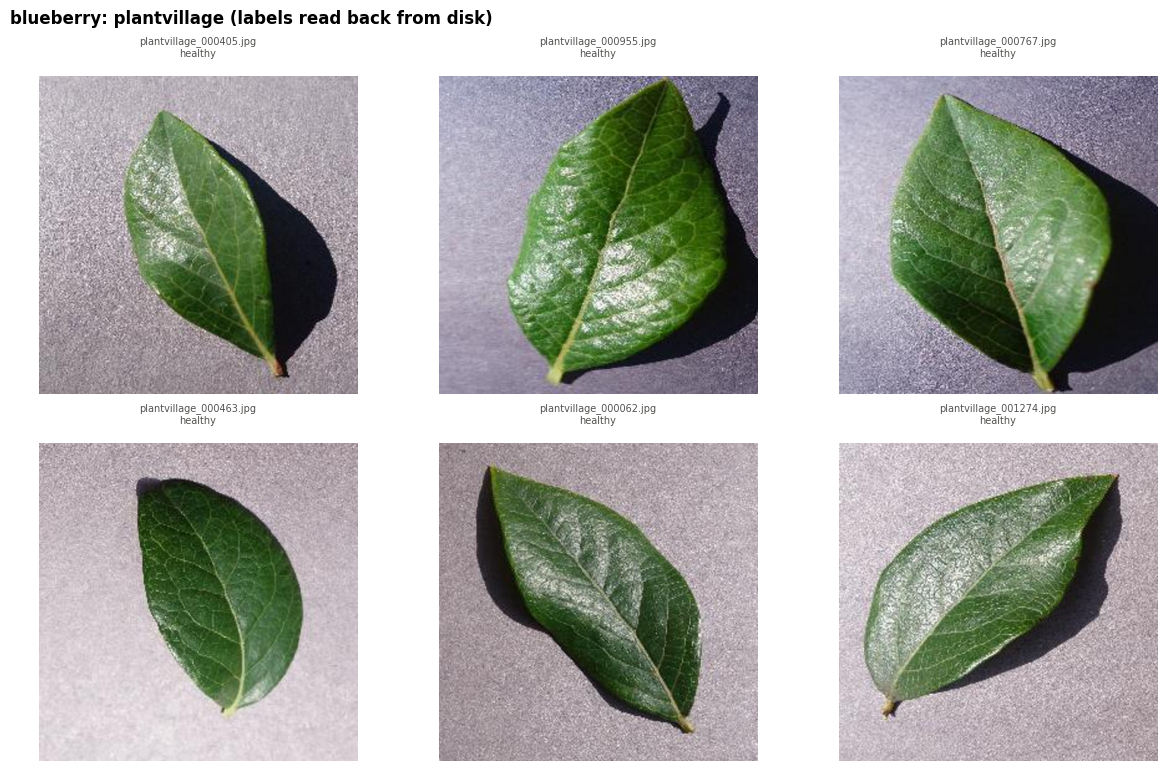

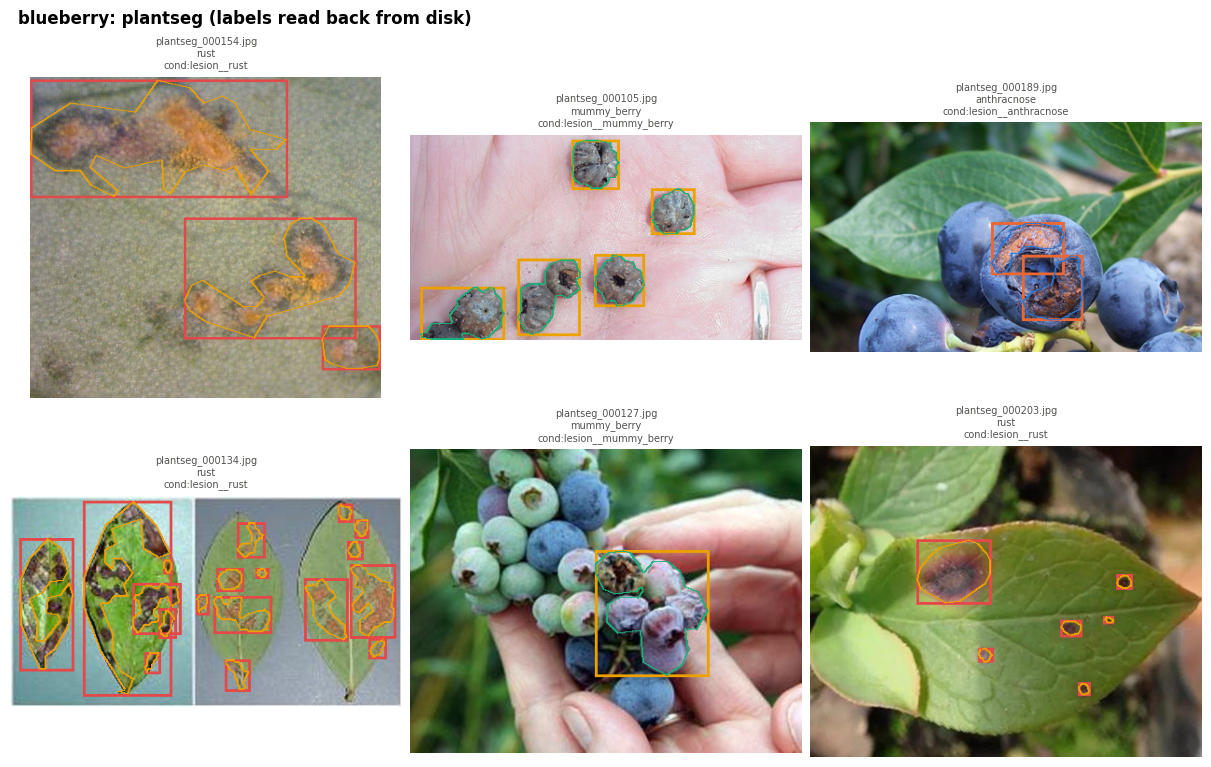

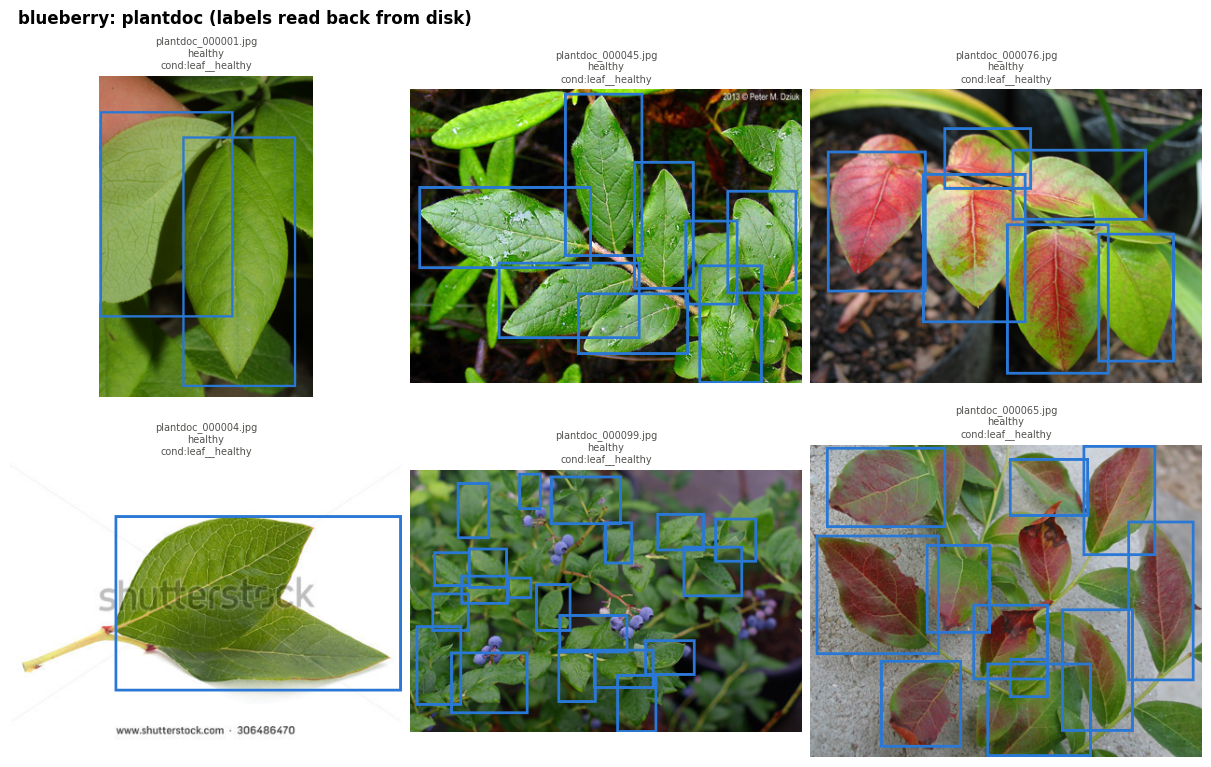

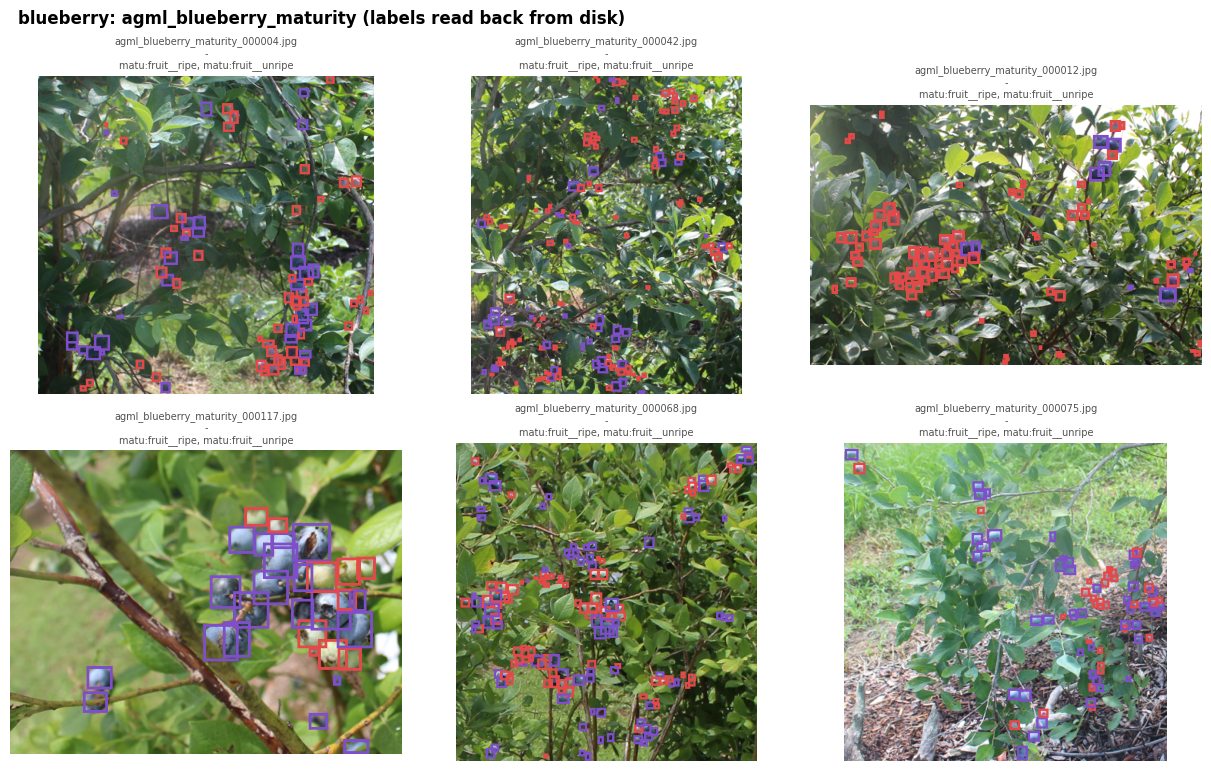

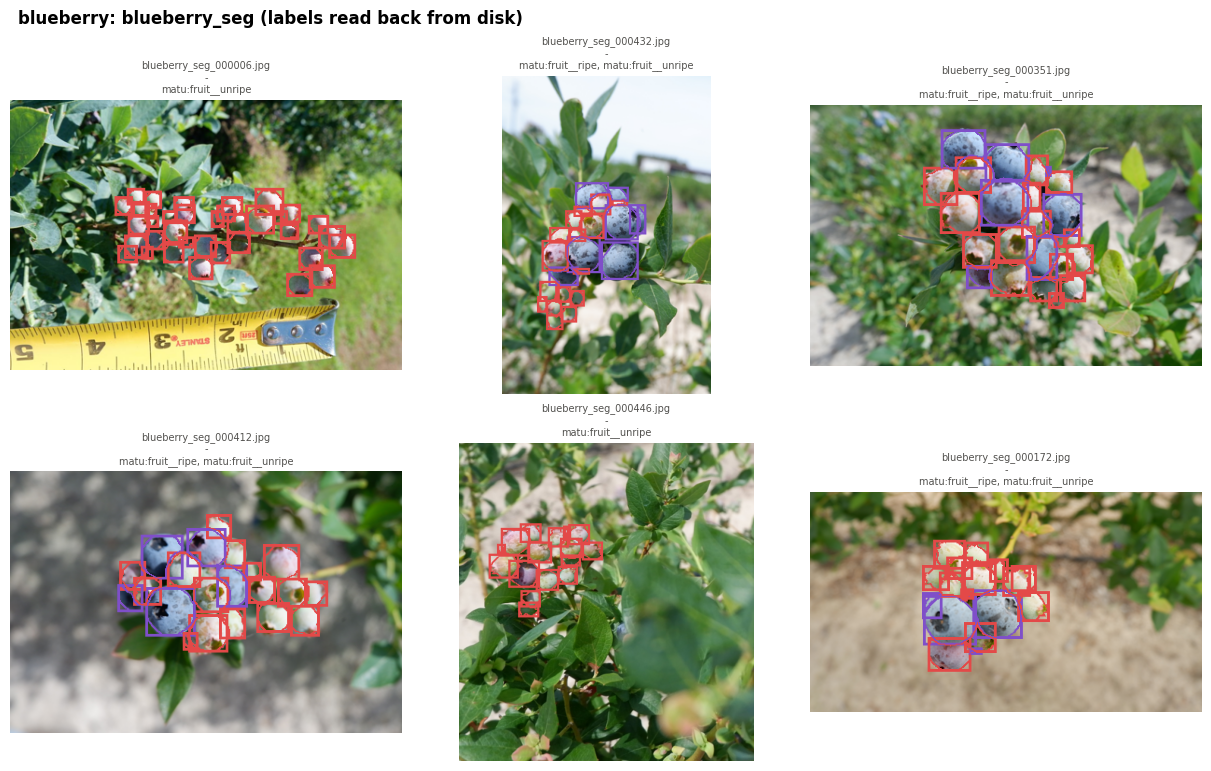

In [12]:
for source in manifest["source"].unique():
    show_roundtrip(source)